# Chapter 3 — Introduction to Neural Prediction: Forward Propagation

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 3, explain the theory, and reproduce all of its code (the **Predict** step).

---

## 1. Chapter Summary

Chapter 3 is about the first step of the learning loop — **making a prediction** (called *forward propagation*). The running example: *"will the team win tonight?"* predicted from information such as number of toes, recent win/loss record and number of fans.

The chapter builds up a neural network in increasing complexity:

| Section | Architecture | Core operation |
|---|---|---|
| A simple network | 1 input → 1 output | `prediction = input * weight` |
| Multiple inputs | N inputs → 1 output | **weighted sum** (dot product) |
| Multiple outputs | 1 input → M outputs | one weight per output |
| Multiple inputs **and** outputs | N inputs → M outputs | **vector-matrix multiplication** |
| Predicting on predictions | stacked layers (hidden layer) | output of layer 1 = input of layer 2 |
| NumPy | everything above | `np.dot`, vectorized code |

Main message: *a neural network is a function that takes numbers in, multiplies them by learned weights, sums, and produces numbers out.* The weights are the "knowledge".

---

## 2. Theory Deep-Dive

### 2.1 The simplest network
$$\hat y = x \cdot w$$
* $x$ — **input data** (information from the world, observed *before* the prediction).
* $w$ — **weight**, a "volume knob": it scales how much the input influences the prediction. $w>1$ amplifies, $0<w<1$ attenuates, $w<0$ flips the sign.
* $\hat y$ — **prediction**.

A network "learns" by finding the right $w$. Not learned yet? That's Chapters 4-5.

### 2.2 Multiple inputs → weighted sum
$$\hat y = \sum_{i} x_i w_i = \mathbf{x}\cdot\mathbf{w}$$
Each input has its own weight — how important is that signal? The **dot product** is the central operation of deep learning. Intuition: it measures *how similar* the input vector is to the weight vector (high when both are large in the same positions).

### 2.3 Multiple outputs
One input drives several independent predictions, each with its own weight:
$$\hat y_j = x \cdot w_j$$
The outputs don't interact — it's just several 1-input networks sharing an input.

### 2.4 Multiple inputs and outputs
Each output has its own weight *vector*. Stacking them gives a **weight matrix** $W$ of shape (outputs × inputs):
$$\hat{\mathbf y} = W\,\mathbf x$$
In the book's convention, a *vector-matrix multiply* loops through rows: each output is the dot product of the input vector with one row of weights.

### 2.5 Predicting on predictions (deeper networks)
The output of one layer can be the input of the next:
$$\mathbf h = W_1 \mathbf x, \qquad \hat{\mathbf y} = W_2 \mathbf h$$
The intermediate vector $\mathbf h$ is the **hidden layer**. Note: with *only* linear layers, $W_2W_1$ collapses into a single matrix — so depth alone gains nothing until we add **non-linearities** (Chapter 6).

### 2.6 Why NumPy?
Same maths, but written as `np.dot`, running in optimized C. All deep learning frameworks are essentially fancy ways of doing this fast on GPUs.

---

## 3. Code Reproduction

### 3.1 Simplest network (1 input → 1 output)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("folder-picture", exist_ok=True)

weight = 0.1
def neural_network(input_, weight):
    prediction = input_ * weight
    return prediction

number_of_toes = [8.5, 9.5, 10, 9]
pred = neural_network(number_of_toes[0], weight)
print("prediction =", pred)

prediction = 0.8500000000000001


### 3.2 Multiple inputs → one output (weighted sum)

Inputs per game: `[toes, win/loss record, number of fans (millions)]`.

In [2]:
def w_sum(a, b):
    assert len(a) == len(b)
    output = 0
    for i in range(len(a)):
        output += a[i] * b[i]
    return output

weights = [0.1, 0.2, 0]

def neural_network(input_, weights):
    return w_sum(input_, weights)

toes   = [8.5, 9.5, 9.9, 9.0]
wlrec  = [0.65, 0.8, 0.8, 0.9]
nfans  = [1.2, 1.3, 0.5, 1.0]

input_ = [toes[0], wlrec[0], nfans[0]]
pred = neural_network(input_, weights)
print("w_sum prediction       :", pred)
print("np.dot (same result)   :", np.dot(input_, weights))

w_sum prediction       : 0.9800000000000001
np.dot (same result)   : 0.9800000000000001


### 3.3 One input → multiple outputs

Predict three things at once: *hurt?*, *win?*, *sad?* from the win/loss record.

In [3]:
def ele_mul(number, vector):
    return [number * v for v in vector]

weights = [0.3, 0.2, 0.9]

def neural_network(input_, weights):
    return ele_mul(input_, weights)

pred = neural_network(wlrec[0], weights)
print("predictions [hurt, win, sad] =", pred)

predictions [hurt, win, sad] = [0.195, 0.13, 0.5850000000000001]


### 3.4 Multiple inputs and multiple outputs (vector–matrix multiplication)

In [4]:
#          toes %win #fans
weights = [[0.1, 0.1, -0.3],   # hurt?
           [0.1, 0.2,  0.0],   # win?
           [0.0, 1.3,  0.1]]   # sad?

def vect_mat_mul(vect, matrix):
    assert len(vect) == len(matrix[0])
    output = [0] * len(matrix)
    for i in range(len(matrix)):
        output[i] = w_sum(vect, matrix[i])
    return output

def neural_network(input_, weights):
    return vect_mat_mul(input_, weights)

input_ = [toes[0], wlrec[0], nfans[0]]
pred = neural_network(input_, weights)
print("pure-python :", pred)
print("numpy       :", np.array(weights).dot(input_))

pure-python : [0.555, 0.9800000000000001, 0.9650000000000001]
numpy       : [0.555 0.98  0.965]


### 3.5 Predicting on predictions (a hidden layer)

In [5]:
ih_wgt = np.array([[0.1, 0.2, -0.1],    # hid[0]
                   [-0.1, 0.1, 0.9],    # hid[1]
                   [0.1, 0.4, 0.1]]).T  # hid[2]   -> shape (inputs, hidden)

hp_wgt = np.array([[0.3, 1.1, -0.3],    # hurt?
                   [0.1, 0.2, 0.0],     # win?
                   [0.0, 1.3, 0.1]]).T  # sad?     -> shape (hidden, outputs)

def neural_network(input_, weights):
    hid  = input_.dot(weights[0])
    pred = hid.dot(weights[1])
    return hid, pred

input_ = np.array([toes[0], wlrec[0], nfans[0]])
hid, pred = neural_network(input_, [ih_wgt, hp_wgt])
print("hidden layer :", hid)
print("prediction   :", pred)

hidden layer : [0.86  0.295 1.23 ]
prediction   : [0.2135 0.145  0.5065]


### 3.6 NumPy-vectorized version — and a visualisation of the weight matrix

predictions for all 4 games:
 [[0.555 0.98  0.965]
 [0.64  1.11  1.17 ]
 [0.92  1.15  1.09 ]
 [0.69  1.08  1.27 ]]


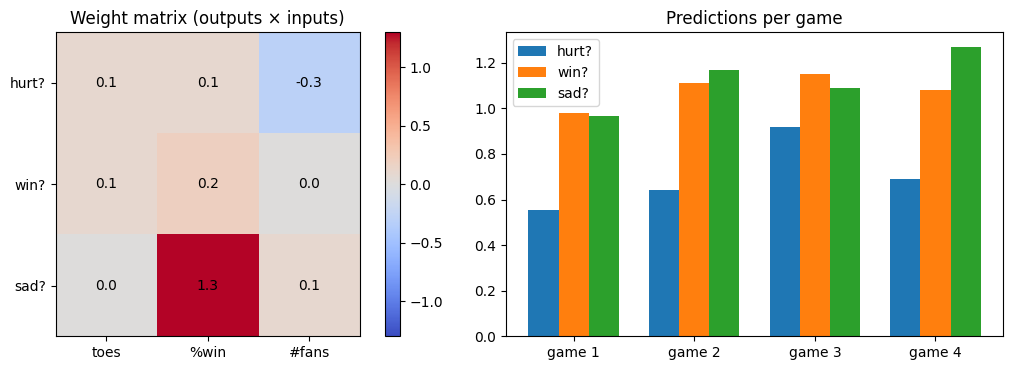

In [6]:
W = np.array([[0.1, 0.1, -0.3],
              [0.1, 0.2,  0.0],
              [0.0, 1.3,  0.1]])
all_games = np.array([toes, wlrec, nfans]).T          # shape (4 games, 3 features)
all_preds = all_games.dot(W.T)                        # predict all 4 games at once
print("predictions for all 4 games:\n", np.round(all_preds, 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
im = ax[0].imshow(W, cmap="coolwarm", vmin=-1.3, vmax=1.3)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["toes", "%win", "#fans"])
ax[0].set_yticks(range(3)); ax[0].set_yticklabels(["hurt?", "win?", "sad?"])
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, W[i, j], ha="center", va="center")
ax[0].set_title("Weight matrix (outputs × inputs)"); plt.colorbar(im, ax=ax[0])

width = 0.25
for j, name in enumerate(["hurt?", "win?", "sad?"]):
    ax[1].bar(np.arange(4) + j * width, all_preds[:, j], width, label=name)
ax[1].set_xticks(np.arange(4) + width); ax[1].set_xticklabels([f"game {i+1}" for i in range(4)])
ax[1].set_title("Predictions per game"); ax[1].legend()
plt.tight_layout()
plt.savefig("folder-picture/ch03_weights_and_predictions.png", dpi=120, bbox_inches="tight")
plt.show()

---

## 4. Key Takeaways

* A neural network's **prediction** is just *numbers × weights, summed*.
* One layer = **vector–matrix multiplication**; stacking layers = **predicting on predictions**.
* The weights hold everything the network "knows". Right now they were chosen by hand — the next two chapters show how to *learn* them.
* NumPy turns the loops into a single `dot`, which is the same operation frameworks use at scale.

➡️ **Next:** Chapter 4 — *comparing* predictions with the truth (error) and a first, crude way to learn: hot and cold.